### Adding Metadata in Ingestion
-  https://docs.databricks.com/aws/en/ingestion/file-metadata-column

To include the _metadata column in the returned DataFrame, you must explicitly select it in your read query when specifying the source.

The _metadata column contains a variety of useful fields. Two common fields include:

- _metadata.file_modification_time – provides the last modification timestamp of the input file
- _metadata.file_name – returns the name of the source file for each row

```python
spark.readStream \
  .format("cloudFiles") \
  .option("cloudFiles.format", "csv") \
  .schema(schema) \
  .load("s3://my-bucket/csvData") \
  .selectExpr("*", "_metadata as source_metadata") \
  .writeStream \
  .option("checkpointLocation", checkpointLocation) \
  .start(targetTable)
```

### Rescued Columns in Ingestion

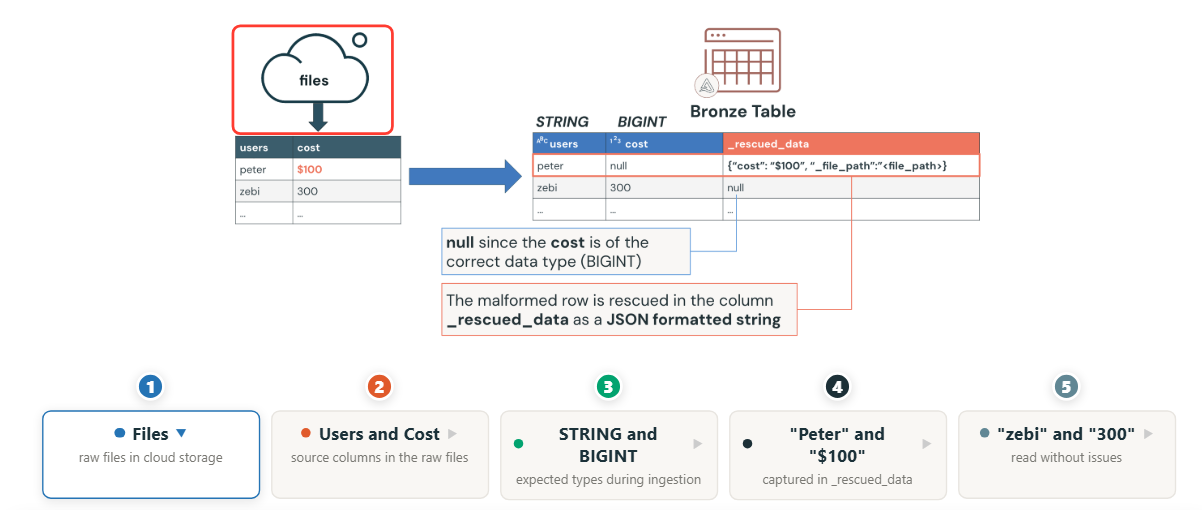

Ingestion techniques like `read_files()`, `spark.read`, or Auto Loader provide a rescued data column during ingestion:

- The rescued data column ensures that columns that do not match the schema are rescued instead of being dropped
- Mismatched values are stored as JSON-formatted strings in the _rescued_data column
- If a row has no schema mismatches, the _rescued_data column will be null
- This preserves all input data and prevents silent data loss

#### Parsng `JSON`
There are three ways we can parse `JSON`s:
1. `STRING` Data Type
    - A column can simply store JSON data as a plain STRING
    - To access subfields within JSON-formatted string columns, you can use the colon (:) syntax.

**For example**, if your column is named json_column, and you want to access the subfield "name", 
- you would specify it as: `json_column:name`


2. `STRUCT` Data Type
    - You can parse JSON data into a STRUCT type by **defining a schema**
    -The STRUCT enforces the JSON schema, ensuring data types and structure are consistent

3. `VARIANT` Data Type
    - The VARIANT data type is the newest approach for working with JSON data in Databricks.

#### Structure of the JSON String
After reviewing how to map a JSON-formatted STRING to a STRUCT column, let's learn how to easily determine the structure of the JSON string.
This can be done in two steps:

- Get the schema of the JSON-formatted string using `schema_of_json`
- Use the `from_json` function to apply the schema and parse the column